# Huấn luyện và đánh giá

## Đọc NHANES

Metric chưa áp trọng số khảo sát.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold

nhanes = pd.read_parquet(Path("../data/processed/nhanes_2015_2018.parquet"))
input_cols = [
    "age", "sex", "race_ethnicity", "bmi", "smoking_status",
    "physical_activity", "heart_attack", "stroke",
]
survey_cols = ["WTINT2YR", "WTMEC2YR", "WTSAF2YR", "SDMVPSU", "SDMVSTRA"]
X = nhanes[input_cols].copy()
y = nhanes["diabetes_label"].copy()
support = nhanes[["SEQN", "cycle"] + survey_cols].copy()
strata = (y.astype("string") + "|" + support["cycle"].astype("string")).rename("strata")

assert X.shape == (10832, 8)
assert X.columns.tolist() == input_cols
assert X.index.equals(y.index) and X.index.equals(support.index)
assert support["SEQN"].notna().all() and support["SEQN"].is_unique
assert support["cycle"].notna().all()
assert y.notna().all() and y.isin([0, 1]).all()
assert strata.nunique() == 4
pd.DataFrame({
    "Số người": [len(X)], "Số đầu vào": [X.shape[1]],
    "Nhãn 0": [int(y.eq(0).sum())], "Nhãn 1": [int(y.eq(1).sum())],
    "Số strata": [strata.nunique()],
})


,Số người,Số đầu vào,Nhãn 0,Nhãn 1,Số strata
0,10832,8,8558,2274,4


## Chia fold

Nested CV gồm 5 fold ngoài để đánh giá và 5 fold trong để chọn tham số, không tách holdout. Phân tầng theo nhãn × chu kỳ; chỉ số vòng trong tương đối với outer-train.

In [2]:
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
outer_splits = [(train_idx.copy(), test_idx.copy())
                for train_idx, test_idx in outer_cv.split(X, strata)]
inner_splits_by_outer = {}
for fold, (outer_train_idx, outer_test_idx) in enumerate(outer_splits, start=1):
    inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    X_outer_train = X.iloc[outer_train_idx]
    strata_outer_train = strata.iloc[outer_train_idx]
    inner_splits_by_outer[fold] = [
        (train_idx.copy(), valid_idx.copy())
        for train_idx, valid_idx in inner_cv.split(X_outer_train, strata_outer_train)
    ]


In [3]:
outer_test_coverage = np.zeros(len(X), dtype=int)
fold_checks = []
for fold, (outer_train_idx, outer_test_idx) in enumerate(outer_splits, start=1):
    assert len(np.intersect1d(outer_train_idx, outer_test_idx)) == 0
    assert np.array_equal(np.sort(np.concatenate([outer_train_idx, outer_test_idx])), np.arange(len(X)))
    train_seqn = set(support.iloc[outer_train_idx]["SEQN"])
    test_seqn = set(support.iloc[outer_test_idx]["SEQN"])
    assert train_seqn.isdisjoint(test_seqn)
    outer_test_coverage[outer_test_idx] += 1

    inner_valid_coverage = np.zeros(len(outer_train_idx), dtype=int)
    assert len(inner_splits_by_outer[fold]) == 5
    for inner_train_idx, inner_valid_idx in inner_splits_by_outer[fold]:
        assert np.array_equal(
            np.sort(np.concatenate([inner_train_idx, inner_valid_idx])),
            np.arange(len(outer_train_idx)),
        )
        assert len(np.intersect1d(inner_train_idx, inner_valid_idx)) == 0
        inner_train_global = outer_train_idx[inner_train_idx]
        inner_valid_global = outer_train_idx[inner_valid_idx]
        assert set(inner_train_global).issubset(set(outer_train_idx))
        assert set(inner_valid_global).issubset(set(outer_train_idx))
        assert len(np.intersect1d(inner_train_global, outer_test_idx)) == 0
        assert len(np.intersect1d(inner_valid_global, outer_test_idx)) == 0
        assert set(support.iloc[inner_train_global]["SEQN"]).isdisjoint(
            set(support.iloc[inner_valid_global]["SEQN"])
        )
        inner_valid_coverage[inner_valid_idx] += 1
    assert np.all(inner_valid_coverage == 1)
    fold_checks.append({
        "Fold ngoài": fold, "Outer-train": len(outer_train_idx),
        "Outer-test": len(outer_test_idx), "Số fold trong": 5,
        "Không giao người": True,
    })
assert len(outer_splits) == 5
assert np.all(outer_test_coverage == 1)
pd.DataFrame(fold_checks)


,Fold ngoài,Outer-train,Outer-test,Số fold trong,Không giao người
0,1,8665,2167,5,True
1,2,8665,2167,5,True
2,3,8666,2166,5,True
3,4,8666,2166,5,True
4,5,8666,2166,5,True


## Số người theo fold

In [4]:
fold_count_tables = []
for fold, (train_idx, test_idx) in enumerate(outer_splits, start=1):
    for split_name, positions in [("Train", train_idx), ("Test", test_idx)]:
        table = pd.crosstab(support.iloc[positions]["cycle"], y.iloc[positions])
        table = table.reindex(columns=[0, 1], fill_value=0).rename(columns={0: "Nhãn 0", 1: "Nhãn 1"})
        table.columns.name = None
        table.index.name = "Chu kỳ"
        table.insert(0, "Số người", table.sum(axis=1))
        table = table.reset_index()
        table.insert(0, "Tập", split_name)
        table.insert(0, "Fold ngoài", fold)
        fold_count_tables.append(table)
outer_fold_counts = pd.concat(fold_count_tables, ignore_index=True)
assert outer_fold_counts["Số người"].eq(outer_fold_counts["Nhãn 0"] + outer_fold_counts["Nhãn 1"]).all()
assert outer_fold_counts.groupby("Fold ngoài")["Số người"].sum().eq(10832).all()
outer_fold_counts


,Fold ngoài,Tập,Chu kỳ,Số người,Nhãn 0,Nhãn 1
0,1,Train,2015-2016,4401,3517,884
1,1,Train,2017-2018,4264,3329,935
2,1,Test,2015-2016,1101,880,221
3,1,Test,2017-2018,1066,832,234
4,2,Train,2015-2016,4401,3517,884
5,2,Train,2017-2018,4264,3329,935
6,2,Test,2015-2016,1101,880,221
7,2,Test,2017-2018,1066,832,234
8,3,Train,2015-2016,4402,3518,884
9,3,Train,2017-2018,4264,3328,936


## Tiền xử lý

| Nhóm | Xử lý |
|---|---|
| age, bmi | Median; thêm StandardScaler cho LR/SVM |
| Sáu biến phân loại | Mode và one-hot, giữ đủ nhóm; nhóm lạ được bỏ qua |

Mỗi lần fit dùng pipeline mới, học tiền xử lý và trọng số lớp từ train của chính fold đó; các bản minh họa không dùng cho CV.

In [5]:
import sys
from importlib import reload

if ".." not in sys.path:
    sys.path.insert(0, "..")
import src.utils as utils
reload(utils)
from src.utils import build_preprocessor

X_before_preprocessor_demo = X.copy(deep=True)
demo_train_idx, demo_test_idx = outer_splits[0]
X_train_demo = X.iloc[demo_train_idx].copy()
X_test_demo = X.iloc[demo_test_idx].copy()
preprocessor_scaled_demo = build_preprocessor(scale_numeric=True)
preprocessor_unscaled_demo = build_preprocessor(scale_numeric=False)
transform_shapes = []
for name, preprocessor in [
    ("LR/SVM: có scaling", preprocessor_scaled_demo),
    ("RF/XGBoost: không scaling", preprocessor_unscaled_demo),
]:
    train_values = preprocessor.fit_transform(X_train_demo)
    names_before_test = preprocessor.get_feature_names_out().copy()
    test_values = preprocessor.transform(X_test_demo)
    np.testing.assert_array_equal(names_before_test, preprocessor.get_feature_names_out())
    assert train_values.shape[1] == test_values.shape[1] == len(names_before_test)
    assert np.isfinite(train_values).all() and np.isfinite(test_values).all()
    transform_shapes.append({
        "Bản kiểm tra": name,
        "Train sau biến đổi": train_values.shape,
        "Test sau biến đổi": test_values.shape,
        "Hữu hạn, không thiếu": True,
    })
pd.DataFrame(transform_shapes)


,Bản kiểm tra,Train sau biến đổi,Test sau biến đổi,"Hữu hạn, không thiếu"
0,LR/SVM: có scaling,"(8665, 17)","(2167, 17)",True
1,RF/XGBoost: không scaling,"(8665, 17)","(2167, 17)",True


In [6]:
numeric_cols = ["age", "bmi"]
train_medians = X_train_demo[numeric_cols].median()
scaled_numeric_demo = preprocessor_scaled_demo.named_transformers_["numeric"]
unscaled_numeric_demo = preprocessor_unscaled_demo.named_transformers_["numeric"]
for numeric_pipeline in [scaled_numeric_demo, unscaled_numeric_demo]:
    np.testing.assert_allclose(numeric_pipeline.named_steps["imputer"].statistics_, train_medians)

filled_train_numeric = X_train_demo[numeric_cols].astype(float).fillna(train_medians)
scaler_demo = scaled_numeric_demo.named_steps["scaler"]
expected_scale = filled_train_numeric.std(ddof=0).replace(0, 1)
np.testing.assert_allclose(scaler_demo.mean_, filled_train_numeric.mean())
np.testing.assert_allclose(scaler_demo.scale_, expected_scale)
pd.DataFrame({
    "Median riêng train": train_medians,
    "Median đã học": scaled_numeric_demo.named_steps["imputer"].statistics_,
    "Scaler mean": scaler_demo.mean_,
    "Scaler scale": scaler_demo.scale_,
})


,Median riêng train,Median đã học,Scaler mean,Scaler scale
age,50.0,50.0,49.207617,18.548138
bmi,28.4,28.4,29.552856,7.153647


In [7]:
categorical_cols = [
    "sex", "race_ethnicity", "smoking_status",
    "physical_activity", "heart_attack", "stroke",
]
train_modes = [X_train_demo[column].mode(dropna=True).iloc[0] for column in categorical_cols]
scaled_modes = preprocessor_scaled_demo.named_transformers_["categorical"].named_steps["imputer"].statistics_
unscaled_modes = preprocessor_unscaled_demo.named_transformers_["categorical"].named_steps["imputer"].statistics_
assert list(scaled_modes) == list(unscaled_modes) == train_modes
pd.DataFrame({
    "Biến": categorical_cols, "Mode riêng train": train_modes, "Mode đã học": scaled_modes,
})


,Biến,Mode riêng train,Mode đã học
0,sex,2,2
1,race_ethnicity,White NH,White NH
2,smoking_status,never,never
3,physical_activity,0,0
4,heart_attack,0,0
5,stroke,0,0


In [8]:
feature_names_demo = preprocessor_scaled_demo.get_feature_names_out()
np.testing.assert_array_equal(
    feature_names_demo, preprocessor_unscaled_demo.get_feature_names_out()
)
pd.DataFrame({
    "Thứ tự": np.arange(1, len(feature_names_demo) + 1),
    "Đặc trưng": feature_names_demo,
})


,Thứ tự,Đặc trưng
0,1,numeric__age
1,2,numeric__bmi
2,3,categorical__sex_1
3,4,categorical__sex_2
4,5,categorical__race_ethnicity_Black NH
5,6,categorical__race_ethnicity_Hispanic
6,7,categorical__race_ethnicity_Other
7,8,categorical__race_ethnicity_White NH
8,9,categorical__smoking_status_current
9,10,categorical__smoking_status_former


In [9]:
pd.testing.assert_frame_equal(X, X_before_preprocessor_demo)
pd.testing.assert_frame_equal(X_train_demo, X.iloc[demo_train_idx])
pd.testing.assert_frame_equal(X_test_demo, X.iloc[demo_test_idx])
assert "scaler" not in unscaled_numeric_demo.named_steps
for preprocessor in [preprocessor_scaled_demo, preprocessor_unscaled_demo]:
    encoder = preprocessor.named_transformers_["categorical"].named_steps["onehot"]
    assert encoder.drop is None and encoder.handle_unknown == "ignore"
fresh_preprocessor_demo = build_preprocessor(scale_numeric=True)
assert fresh_preprocessor_demo is not preprocessor_scaled_demo
assert not hasattr(fresh_preprocessor_demo, "transformers_")
assert fresh_preprocessor_demo.transformers[0][1] is not preprocessor_scaled_demo.transformers[0][1]
pd.Series({
    "Median/mode chỉ từ train": True,
    "Mean/scale chỉ từ train đã điền median": True,
    "Train/test cùng số cột và thứ tự": True,
    "X gốc không đổi": True,
    "Hàm tạo đối tượng mới, chưa fit": True,
}, name="Đạt kiểm tra").to_frame()


,Đạt kiểm tra
Median/mode chỉ từ train,True
Mean/scale chỉ từ train đã điền median,True
Train/test cùng số cột và thứ tự,True
X gốc không đổi,True
"Hàm tạo đối tượng mới, chưa fit",True


## LR baseline

Cấu hình cố định dùng làm mốc so với kết quả tối ưu.

In [10]:
import warnings
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss, confusion_matrix,
)

from src.utils import get_model_metrics

X_before_lr_baseline = X.copy(deep=True)
y_before_lr_baseline = y.copy(deep=True)
lr_oof_probability = pd.Series(np.nan, index=X.index, name="probability_1")
lr_oof_fold = pd.Series(pd.NA, index=X.index, dtype="Int64", name="outer_fold")
lr_oof_coverage = np.zeros(len(X), dtype=int)
lr_baseline_models = {}
lr_fold_rows = []
lr_warning_rows = []
for fold, (train_idx, test_idx) in enumerate(outer_splits, start=1):
    X_train = X.iloc[train_idx]
    y_train = y.iloc[train_idx]
    X_test = X.iloc[test_idx]
    y_test = y.iloc[test_idx]
    model = Pipeline([
        ("preprocessor", build_preprocessor(scale_numeric=True)),
        ("classifier", LogisticRegression(
            C=1.0, class_weight="balanced", solver="lbfgs",
            max_iter=2000, random_state=42,
        )),
    ])
    assert model.named_steps["preprocessor"] is not preprocessor_scaled_demo
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        model.fit(X_train, y_train)
    for warning in caught:
        lr_warning_rows.append({
            "Fold": fold, "Loại": warning.category.__name__,
            "Thông báo": str(warning.message),
            "Không hội tụ": issubclass(warning.category, ConvergenceWarning),
        })
    weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train.to_numpy(dtype=int))
    np.testing.assert_allclose(weights, [len(y_train) / (2 * y_train.eq(label).sum()) for label in [0, 1]])
    positive_column = int(np.flatnonzero(model.classes_ == 1)[0])
    probability = model.predict_proba(X_test)[:, positive_column]
    prediction = (probability >= 0.5).astype(int)
    assert np.isfinite(probability).all() and ((probability >= 0) & (probability <= 1)).all()
    lr_oof_probability.iloc[test_idx] = probability
    lr_oof_fold.iloc[test_idx] = fold
    lr_oof_coverage[test_idx] += 1
    lr_fold_rows.append({
        "Fold": fold,
        **get_model_metrics(y_test, probability, probability, prediction),
    })
    lr_baseline_models[fold] = model
lr_fold_metrics = pd.DataFrame(lr_fold_rows).set_index("Fold")
lr_fold_metrics.round(4)


,ROC-AUC,Average precision,Sensitivity,Specificity,Precision,F1,Brier score
Fold,,,,,,,
1,0.7789,0.4383,0.7451,0.6665,0.3725,0.4967,0.1977
2,0.7932,0.4698,0.7736,0.6846,0.3946,0.5226,0.1899
3,0.7981,0.4575,0.7819,0.6887,0.3998,0.5291,0.1901
4,0.7935,0.4599,0.7495,0.6856,0.3879,0.5112,0.1869
5,0.8128,0.4953,0.7978,0.6973,0.4120,0.5434,0.1810


In [11]:
lr_metric_summary = lr_fold_metrics.agg(["mean", "std"]).rename(
    index={"mean": "Trung bình", "std": "Độ lệch chuẩn"}
)
lr_metric_summary.round(4)


,ROC-AUC,Average precision,Sensitivity,Specificity,Precision,F1,Brier score
Trung bình,0.7953,0.4642,0.7696,0.6845,0.3934,0.5206,0.1891
Độ lệch chuẩn,0.0121,0.0208,0.0222,0.0112,0.0146,0.0177,0.0060


In [12]:
assert lr_oof_probability.index.equals(X.index) and lr_oof_probability.index.equals(y.index)
assert lr_oof_probability.notna().all() and lr_oof_fold.notna().all()
assert np.isfinite(lr_oof_probability).all()
assert lr_oof_probability.between(0, 1).all()
assert np.all(lr_oof_coverage == 1)
lr_oof_prediction = lr_oof_probability.ge(0.5).astype("Int64").rename("prediction")
lr_oof = pd.DataFrame({
    "SEQN": support["SEQN"], "cycle": support["cycle"],
    "y_true": y, "probability_1": lr_oof_probability,
    "prediction": lr_oof_prediction, "outer_fold": lr_oof_fold,
})
assert lr_oof.index.equals(X.index) and lr_oof["SEQN"].is_unique
assert len(lr_oof) == 10832
for fold, (_, test_idx) in enumerate(outer_splits, start=1):
    assert lr_oof_fold.iloc[test_idx].eq(fold).all()
    assert set(lr_oof.loc[lr_oof["outer_fold"].eq(fold), "SEQN"]) == set(support.iloc[test_idx]["SEQN"])
pd.DataFrame(
    confusion_matrix(y, lr_oof_prediction, labels=[0, 1]),
    index=pd.Index(["0", "1"], name="Nhãn thật"),
    columns=pd.Index(["0", "1"], name="Dự đoán (ngưỡng 0,5)"),
)


"Dự đoán (ngưỡng 0,5)",0,1
Nhãn thật,,
0,5858,2700
1,524,1750


In [13]:
pd.testing.assert_frame_equal(X, X_before_lr_baseline)
pd.testing.assert_series_equal(y, y_before_lr_baseline)
assert len({id(m.named_steps["preprocessor"]) for m in lr_baseline_models.values()}) == 5
assert len({id(m.named_steps["classifier"]) for m in lr_baseline_models.values()}) == 5
lr_baseline_warnings = pd.DataFrame(lr_warning_rows, columns=["Fold", "Loại", "Thông báo", "Không hội tụ"])
lr_convergence_warnings = sum(row["Không hội tụ"] for row in lr_warning_rows)
pd.Series({
    "Số dự đoán ngoài fold": len(lr_oof_probability),
    "Dự đoán thiếu": int(lr_oof_probability.isna().sum()),
    "Mỗi người được dự đoán đúng một lần": bool(np.all(lr_oof_coverage == 1)),
    "X/y giữ nguyên": True,
    "Số cảnh báo": len(lr_baseline_warnings),
    "Cảnh báo không hội tụ": lr_convergence_warnings,
}, name="Kiểm tra").to_frame()


,Kiểm tra
Số dự đoán ngoài fold,10832
Dự đoán thiếu,0
Mỗi người được dự đoán đúng một lần,True
X/y giữ nguyên,True
Số cảnh báo,0
Cảnh báo không hội tụ,0


In [14]:
lr_baseline_warnings


,Fold,Loại,Thông báo,Không hội tụ


Trung bình ± SD tính giữa 5 fold với `ddof=1`; SD không phải khoảng tin cậy. Confusion matrix dùng OOF gộp.

## XGBoost baseline

Cấu hình baseline do dự án chọn, không phải cấu hình tối ưu của paper.

In [15]:
import sys
from time import perf_counter
import sklearn
import xgboost
from xgboost import XGBClassifier

xgb_environment = pd.Series({
    "Python": sys.executable,
    "xgboost": xgboost.__version__,
    "scikit-learn": sklearn.__version__,
}, name="Môi trường")
xgb_environment.to_frame()


,Môi trường
Python,D:\NCKH Mini\.venv\Scripts\python.exe
xgboost,3.4.1
scikit-learn,1.9.1


In [16]:
X_before_xgb_baseline = X.copy(deep=True)
y_before_xgb_baseline = y.copy(deep=True)
xgb_oof_probability = pd.Series(np.nan, index=X.index, name="probability_1")
xgb_oof_fold = pd.Series(pd.NA, index=X.index, dtype="Int64", name="outer_fold")
xgb_oof_coverage = np.zeros(len(X), dtype=int)
xgb_baseline_models = {}
xgb_fold_rows = []
xgb_fit_rows = []
xgb_warning_rows = []
for fold, (train_idx, test_idx) in enumerate(outer_splits, start=1):
    X_train = X.iloc[train_idx]
    y_train = y.iloc[train_idx]
    X_test = X.iloc[test_idx]
    y_test = y.iloc[test_idx]
    n_negative = int(y_train.eq(0).sum())
    n_positive = int(y_train.eq(1).sum())
    assert n_positive > 0
    scale_pos_weight = n_negative / n_positive
    model = Pipeline([
        ("preprocessor", build_preprocessor(scale_numeric=False)),
        ("classifier", XGBClassifier(
            objective="binary:logistic", eval_metric="logloss",
            n_estimators=200, max_depth=3, learning_rate=0.05,
            min_child_weight=1, subsample=0.8, colsample_bytree=0.8,
            reg_alpha=0, reg_lambda=1, tree_method="hist",
            random_state=42, n_jobs=4, scale_pos_weight=scale_pos_weight,
        )),
    ])
    assert model.named_steps["preprocessor"] is not preprocessor_unscaled_demo
    assert model.named_steps["preprocessor"] is not lr_baseline_models[fold].named_steps["preprocessor"]
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        fit_start = perf_counter()
        model.fit(X_train, y_train)
        fit_seconds = perf_counter() - fit_start
    for warning in caught:
        xgb_warning_rows.append({
            "Fold": fold, "Loại": warning.category.__name__, "Thông báo": str(warning.message),
        })
    classifier = model.named_steps["classifier"]
    assert classifier.get_params()["scale_pos_weight"] == n_negative / n_positive
    assert classifier.get_params().get("early_stopping_rounds") is None
    assert classifier.get_booster().num_boosted_rounds() == 200
    assert "scaler" not in model.named_steps["preprocessor"].named_transformers_["numeric"].named_steps
    positive_column = int(np.flatnonzero(model.classes_ == 1)[0])
    probability = model.predict_proba(X_test)[:, positive_column]
    prediction = (probability >= 0.5).astype(int)
    assert np.isfinite(probability).all() and ((probability >= 0) & (probability <= 1)).all()
    xgb_oof_probability.iloc[test_idx] = probability
    xgb_oof_fold.iloc[test_idx] = fold
    xgb_oof_coverage[test_idx] += 1
    xgb_fold_rows.append({
        "Fold": fold,
        **get_model_metrics(y_test, probability, probability, prediction),
    })
    xgb_fit_rows.append({
        "Fold": fold, "Train nhãn 0": n_negative, "Train nhãn 1": n_positive,
        "scale_pos_weight": scale_pos_weight, "Fit pipeline (giây)": fit_seconds,
    })
    xgb_baseline_models[fold] = model
xgb_fold_metrics = pd.DataFrame(xgb_fold_rows).set_index("Fold")
xgb_fold_metrics.round(4)


,ROC-AUC,Average precision,Sensitivity,Specificity,Precision,F1,Brier score
Fold,,,,,,,
1,0.7833,0.4594,0.7758,0.6449,0.3673,0.4986,0.1940
2,0.7969,0.4894,0.7802,0.6735,0.3884,0.5186,0.1870
3,0.8045,0.4882,0.8194,0.6466,0.3808,0.5199,0.1881
4,0.8059,0.4759,0.7890,0.6873,0.4016,0.5322,0.1815
5,0.8097,0.4898,0.8198,0.6680,0.3964,0.5344,0.1821


In [17]:
xgb_fit_times = pd.DataFrame(xgb_fit_rows).set_index("Fold")
xgb_fit_times.round({"scale_pos_weight": 6, "Fit pipeline (giây)": 3})


,Train nhãn 0,Train nhãn 1,scale_pos_weight,Fit pipeline (giây)
Fold,,,,
1,6846,1819,3.763606,0.153
2,6846,1819,3.763606,0.076
3,6846,1820,3.761538,0.078
4,6847,1819,3.764156,0.078
5,6847,1819,3.764156,0.084


In [18]:
xgb_metric_summary = xgb_fold_metrics.agg(["mean", "std"]).rename(
    index={"mean": "Trung bình", "std": "Độ lệch chuẩn"}
)
xgb_metric_summary.round(4)


,ROC-AUC,Average precision,Sensitivity,Specificity,Precision,F1,Brier score
Trung bình,0.8000,0.4805,0.7968,0.6641,0.3869,0.5208,0.1866
Độ lệch chuẩn,0.0105,0.0131,0.0213,0.0182,0.0135,0.0143,0.0051


In [19]:
baseline_comparison = pd.DataFrame({
    name: metrics.agg(["mean", "std"]).T.apply(
        lambda row: f"{row['mean']:.4f} ± {row['std']:.4f}", axis=1
    )
    for name, metrics in [("LR", lr_fold_metrics), ("XGBoost", xgb_fold_metrics)]
})
baseline_comparison.index.name = "Metric"
baseline_comparison


,LR,XGBoost
Metric,,
ROC-AUC,0.7953 ± 0.0121,0.8000 ± 0.0105
Average precision,0.4642 ± 0.0208,0.4805 ± 0.0131
Sensitivity,0.7696 ± 0.0222,0.7968 ± 0.0213
Specificity,0.6845 ± 0.0112,0.6641 ± 0.0182
Precision,0.3934 ± 0.0146,0.3869 ± 0.0135
F1,0.5206 ± 0.0177,0.5208 ± 0.0143
Brier score,0.1891 ± 0.0060,0.1866 ± 0.0051


In [20]:
assert xgb_oof_probability.index.equals(X.index) and xgb_oof_probability.index.equals(y.index)
assert xgb_oof_probability.notna().all() and xgb_oof_fold.notna().all()
assert np.isfinite(xgb_oof_probability).all()
assert xgb_oof_probability.between(0, 1).all()
assert np.all(xgb_oof_coverage == 1)
xgb_oof_prediction = xgb_oof_probability.ge(0.5).astype("Int64").rename("prediction")
xgb_oof = pd.DataFrame({
    "SEQN": support["SEQN"], "cycle": support["cycle"],
    "y_true": y, "probability_1": xgb_oof_probability,
    "prediction": xgb_oof_prediction, "outer_fold": xgb_oof_fold,
})
assert xgb_oof.index.equals(X.index) and xgb_oof["SEQN"].is_unique
assert len(xgb_oof) == 10832
pd.testing.assert_series_equal(xgb_oof["outer_fold"], lr_oof["outer_fold"])
pd.testing.assert_frame_equal(xgb_oof[["SEQN", "cycle", "y_true"]], lr_oof[["SEQN", "cycle", "y_true"]])
for fold, (_, test_idx) in enumerate(outer_splits, start=1):
    assert xgb_oof_fold.iloc[test_idx].eq(fold).all()
    assert set(xgb_oof.loc[xgb_oof["outer_fold"].eq(fold), "SEQN"]) == set(support.iloc[test_idx]["SEQN"])
xgb_confusion = pd.DataFrame(
    confusion_matrix(y, xgb_oof_prediction, labels=[0, 1]),
    index=pd.Index(["0", "1"], name="Nhãn thật"),
    columns=pd.Index(["0", "1"], name="Dự đoán (ngưỡng 0,5)"),
)
xgb_confusion


"Dự đoán (ngưỡng 0,5)",0,1
Nhãn thật,,
0,5683,2875
1,462,1812


In [21]:
pd.testing.assert_frame_equal(X, X_before_xgb_baseline)
pd.testing.assert_series_equal(y, y_before_xgb_baseline)
assert len({id(m.named_steps["preprocessor"]) for m in xgb_baseline_models.values()}) == 5
assert len({id(m.named_steps["classifier"]) for m in xgb_baseline_models.values()}) == 5
xgb_baseline_warnings = pd.DataFrame(xgb_warning_rows, columns=["Fold", "Loại", "Thông báo"])
pd.Series({
    "Số dự đoán ngoài fold": len(xgb_oof_probability),
    "Dự đoán thiếu": int(xgb_oof_probability.isna().sum()),
    "Mỗi người được dự đoán đúng một lần": bool(np.all(xgb_oof_coverage == 1)),
    "Cùng người và fold với LR": True,
    "X/y giữ nguyên": True,
    "Số cảnh báo XGBoost": len(xgb_baseline_warnings),
}, name="Kiểm tra").to_frame()


,Kiểm tra
Số dự đoán ngoài fold,10832
Dự đoán thiếu,0
Mỗi người được dự đoán đúng một lần,True
Cùng người và fold với LR,True
X/y giữ nguyên,True
Số cảnh báo XGBoost,0


In [22]:
xgb_baseline_warnings


,Fold,Loại,Thông báo


Thời gian fit gồm tiền xử lý và classifier.

## RF và SVM baseline

LR/RF/XGBoost phân loại bằng xác suất ≥0,5; SVM dùng decision score ≥0 và dùng score cho ROC-AUC/AP. Brier dùng xác suất; `probability=True` của SVM có ước lượng xác suất nội bộ, nên score 0 không tương đương xác suất 0,5.

In [23]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

required_baseline_results = ["lr_fold_metrics", "xgb_fold_metrics", "lr_oof", "xgb_oof"]
missing_baseline_results = [name for name in required_baseline_results if name not in globals()]
if missing_baseline_results:
    raise RuntimeError(f"Cần chạy các ô LR/XGBoost trước: {missing_baseline_results}")
for old_oof in [lr_oof, xgb_oof]:
    assert old_oof.index.equals(X.index) and old_oof.index.equals(y.index)
    pd.testing.assert_series_equal(old_oof["SEQN"], support["SEQN"])
    pd.testing.assert_series_equal(old_oof["y_true"], y.rename("y_true"))
    for fold, (_, test_idx) in enumerate(outer_splits, start=1):
        assert old_oof["outer_fold"].iloc[test_idx].eq(fold).all()
assert lr_fold_metrics.index.tolist() == xgb_fold_metrics.index.tolist() == [1, 2, 3, 4, 5]
assert np.isfinite(lr_fold_metrics.to_numpy()).all() and np.isfinite(xgb_fold_metrics.to_numpy()).all()

X_before_rf_svm = X.copy(deep=True)
y_before_rf_svm = y.copy(deep=True)
rf_svm_configs = {
    "RF": (False, RandomForestClassifier, {
        "n_estimators": 300, "max_depth": None, "min_samples_leaf": 5,
        "max_features": "sqrt", "class_weight": "balanced",
        "random_state": 42, "n_jobs": 4,
    }),
    "SVM RBF": (True, SVC, {
        "C": 1.0, "kernel": "rbf", "gamma": "scale",
        "class_weight": "balanced", "probability": True, "random_state": 42,
    }),
}


In [24]:
rf_svm_models = {}
rf_svm_oof = {}
rf_svm_fold_metrics = {}
rf_svm_fit_rows = []
rf_svm_warning_rows = []
rf_svm_check_rows = []
for model_name, (scale_numeric, classifier_type, params) in rf_svm_configs.items():
    oof_probability = pd.Series(np.nan, index=X.index, name="probability_1")
    oof_score = pd.Series(np.nan, index=X.index, name="score")
    oof_prediction = pd.Series(pd.NA, index=X.index, dtype="Int64", name="prediction")
    oof_fold = pd.Series(pd.NA, index=X.index, dtype="Int64", name="outer_fold")
    coverage = np.zeros(len(X), dtype=int)
    fold_rows = []
    rf_svm_models[model_name] = {}
    for fold, (train_idx, test_idx) in enumerate(outer_splits, start=1):
        X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
        X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]
        model = Pipeline([
            ("preprocessor", build_preprocessor(scale_numeric=scale_numeric)),
            ("classifier", classifier_type(**params)),
        ])
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            fit_start = perf_counter()
            model.fit(X_train, y_train)
            fit_seconds = perf_counter() - fit_start
        for warning in caught:
            rf_svm_warning_rows.append({
                "Mô hình": model_name, "Fold": fold, "Loại": warning.category.__name__,
                "Thông báo": str(warning.message),
                "Không hội tụ": issubclass(warning.category, ConvergenceWarning),
            })
        classifier = model.named_steps["classifier"]
        assert classifier.class_weight == "balanced"
        np.testing.assert_array_equal(model.classes_, [0, 1])
        probability = model.predict_proba(X_test)[:, 1]
        if model_name == "SVM RBF":
            score = model.decision_function(X_test)
            prediction = (score >= 0).astype(int)
            expected_weights = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train.to_numpy(dtype=int))
            np.testing.assert_allclose(classifier.class_weight_, expected_weights)
            assert classifier.fit_status_ == 0
        else:
            score = probability
            prediction = (probability >= 0.5).astype(int)
        assert np.isfinite(score).all() and np.isfinite(probability).all()
        assert ((probability >= 0) & (probability <= 1)).all()
        oof_probability.iloc[test_idx] = probability
        oof_score.iloc[test_idx] = score
        oof_prediction.iloc[test_idx] = prediction
        oof_fold.iloc[test_idx] = fold
        coverage[test_idx] += 1
        fold_rows.append({
            "Fold": fold,
            **get_model_metrics(y_test, score, probability, prediction),
        })
        rf_svm_fit_rows.append({"Mô hình": model_name, "Fold": fold, "Fit pipeline (giây)": fit_seconds})
        rf_svm_models[model_name][fold] = model
    assert np.all(coverage == 1)
    assert oof_probability.notna().all() and oof_score.notna().all() and oof_prediction.notna().all()
    result = pd.DataFrame({
        "SEQN": support["SEQN"], "cycle": support["cycle"], "y_true": y,
        "score": oof_score, "probability_1": oof_probability,
        "prediction": oof_prediction, "outer_fold": oof_fold,
    })
    assert result.index.equals(X.index) and result.index.equals(y.index)
    assert result["SEQN"].is_unique and len(result) == 10832
    pd.testing.assert_frame_equal(result[["SEQN", "cycle", "y_true", "outer_fold"]], lr_oof[["SEQN", "cycle", "y_true", "outer_fold"]])
    rf_svm_oof[model_name] = result
    rf_svm_fold_metrics[model_name] = pd.DataFrame(fold_rows).set_index("Fold")
    rf_svm_check_rows.append({
        "Mô hình": model_name, "Số dự đoán": len(result),
        "Dự đoán thiếu": int(result["probability_1"].isna().sum()),
        "Đúng một lần/người": bool(np.all(coverage == 1)),
        "Cùng người/fold với LR": True,
    })
rf_fold_metrics = rf_svm_fold_metrics["RF"]
svm_fold_metrics = rf_svm_fold_metrics["SVM RBF"]
pd.concat(rf_svm_fold_metrics, names=["Mô hình"]).round(4)


ROC-AUC  Average precision  Sensitivity  Specificity  Precision  \
Mô hình Fold                                                                    
RF      1      0.7683             0.4249       0.7121       0.6805     0.3720   
        2      0.7794             0.4448       0.6989       0.7120     0.3921   
        3      0.7929             0.4588       0.7511       0.6904     0.3915   
        4      0.7835             0.4365       0.6571       0.7218     0.3858   
        5      0.7932             0.4606       0.7253       0.7171     0.4054   
SVM RBF 1      0.7773             0.4264       0.7912       0.6367     0.3666   
        2      0.7822             0.4354       0.7890       0.6478     0.3732   
        3      0.7922             0.4491       0.8392       0.6373     0.3802   
        4      0.7879             0.4329       0.7978       0.6581     0.3829   
        5      0.8054             0.4757       0.8330       0.6458     0.3848   

                  F1  Brier score  
Mô hình Fold                       
RF      1     0.4887       0.1872  
        2     0.5024       0.1805  
        3     0.5147       0.1800  
        4     0.4862       0.1764  
        5     0.5201       0.1755  
SVM RBF 1     0.5010       0.1402  
        2     0.5067       0.1387  
        3     0.5234       0.1361  
        4     0.5175       0.1379  
        5     0.5264       0.1329

In [25]:
rf_metric_summary = rf_fold_metrics.agg(["mean", "std"])
svm_metric_summary = svm_fold_metrics.agg(["mean", "std"])
pd.concat({
    "RF": rf_metric_summary, "SVM RBF": svm_metric_summary,
}, names=["Mô hình"]).rename(index={"mean": "Trung bình", "std": "Độ lệch chuẩn"}).round(4)


ROC-AUC  Average precision  Sensitivity  Specificity  \
Mô hình                                                                       
RF      Trung bình      0.7834             0.4451       0.7089       0.7044   
        Độ lệch chuẩn   0.0104             0.0151       0.0348       0.0180   
SVM RBF Trung bình      0.7890             0.4439       0.8100       0.6451   
        Độ lệch chuẩn   0.0108             0.0196       0.0241       0.0088   

                       Precision      F1  Brier score  
Mô hình                                                
RF      Trung bình        0.3894  0.5024       0.1799  
        Độ lệch chuẩn     0.0121  0.0151       0.0046  
SVM RBF Trung bình        0.3775  0.5150       0.1372  
        Độ lệch chuẩn     0.0075  0.0108       0.0028

In [26]:
rf_svm_fit_times = pd.DataFrame(rf_svm_fit_rows).pivot(
    index="Fold", columns="Mô hình", values="Fit pipeline (giây)"
)
rf_svm_fit_times.round(3)


Mô hình,RF,SVM RBF
Fold,,
1,0.491,7.499
2,0.480,7.343
3,0.480,7.386
4,0.470,7.407
5,0.490,7.520


In [27]:
rf_svm_confusion = pd.concat({
    name: pd.DataFrame(
        confusion_matrix(y, result["prediction"], labels=[0, 1]),
        index=pd.Index(["0", "1"], name="Nhãn thật"),
        columns=pd.Index(["0", "1"], name="Dự đoán"),
    )
    for name, result in rf_svm_oof.items()
}, names=["Mô hình"])
rf_svm_confusion


Dự đoán               0     1
Mô hình Nhãn thật            
RF      0          6028  2530
        1           662  1612
SVM RBF 0          5521  3037
        1           432  1842

In [28]:
all_baseline_metrics = {
    "LR": lr_fold_metrics, "XGBoost": xgb_fold_metrics,
    "RF": rf_fold_metrics, "SVM RBF": svm_fold_metrics,
}
baseline_comparison = pd.DataFrame({
    name: metrics.agg(["mean", "std"]).T.apply(
        lambda row: f"{row['mean']:.4f} ± {row['std']:.4f}", axis=1
    )
    for name, metrics in all_baseline_metrics.items()
})
baseline_comparison.index.name = "Metric"
baseline_comparison


,LR,XGBoost,RF,SVM RBF
Metric,,,,
ROC-AUC,0.7953 ± 0.0121,0.8000 ± 0.0105,0.7834 ± 0.0104,0.7890 ± 0.0108
Average precision,0.4642 ± 0.0208,0.4805 ± 0.0131,0.4451 ± 0.0151,0.4439 ± 0.0196
Sensitivity,0.7696 ± 0.0222,0.7968 ± 0.0213,0.7089 ± 0.0348,0.8100 ± 0.0241
Specificity,0.6845 ± 0.0112,0.6641 ± 0.0182,0.7044 ± 0.0180,0.6451 ± 0.0088
Precision,0.3934 ± 0.0146,0.3869 ± 0.0135,0.3894 ± 0.0121,0.3775 ± 0.0075
F1,0.5206 ± 0.0177,0.5208 ± 0.0143,0.5024 ± 0.0151,0.5150 ± 0.0108
Brier score,0.1891 ± 0.0060,0.1866 ± 0.0051,0.1799 ± 0.0046,0.1372 ± 0.0028


In [29]:
pd.testing.assert_frame_equal(X, X_before_rf_svm)
pd.testing.assert_series_equal(y, y_before_rf_svm)
all_new_models = [model for models in rf_svm_models.values() for model in models.values()]
assert len({id(m.named_steps["preprocessor"]) for m in all_new_models}) == 10
assert len({id(m.named_steps["classifier"]) for m in all_new_models}) == 10
rf_svm_warnings = pd.DataFrame(rf_svm_warning_rows, columns=[
    "Mô hình", "Fold", "Loại", "Thông báo", "Không hội tụ",
])
rf_svm_checks = pd.DataFrame(rf_svm_check_rows).set_index("Mô hình")
rf_svm_checks["X/y không đổi"] = True
rf_svm_checks["Cảnh báo không hội tụ"] = [
    sum(row["Không hội tụ"] for row in rf_svm_warning_rows if row["Mô hình"] == name)
    for name in rf_svm_checks.index
]
rf_svm_checks


,Số dự đoán,Dự đoán thiếu,Đúng một lần/người,Cùng người/fold với LR,X/y không đổi,Cảnh báo không hội tụ
Mô hình,,,,,,
RF,10832,0,True,True,True,0
SVM RBF,10832,0,True,True,True,0


In [30]:
rf_svm_warnings


,Mô hình,Fold,Loại,Thông báo,Không hội tụ
0,SVM RBF,1,FutureWarning,The `probability` parameter was deprecated in ...,False
1,SVM RBF,2,FutureWarning,The `probability` parameter was deprecated in ...,False
2,SVM RBF,3,FutureWarning,The `probability` parameter was deprecated in ...,False
3,SVM RBF,4,FutureWarning,The `probability` parameter was deprecated in ...,False
4,SVM RBF,5,FutureWarning,The `probability` parameter was deprecated in ...,False


## Miền tìm kiếm

Paper `2607.16253v1.pdf`, trang 2, mục II.D dùng Bayesian optimization 100 lượt/fold và nêu sáu khoảng XGBoost dưới đây. Miền LR/RF/SVM, cách lấy mẫu, Optuna TPE và ngân sách 30 trial COMPLETE là lựa chọn của dự án.

| Mô hình | Miền tham số |
|---|---|
| LR | `C`: 0,001–100 (log) |
| RF | Số cây: 200–600, bước 100; độ sâu: None/5/10/20; `min_samples_leaf`: 1–20; `min_samples_split`: 2–20; `max_features`: sqrt/0,5/1,0 |
| SVM RBF | `C`: 0,01–100 (log); `gamma`: 0,0001–1 (log) |
| XGBoost | `learning_rate`: 0,01–0,20; `max_depth`: 3–9; `n_estimators`: 100–500; `subsample`, `colsample_bytree`: 0,6–1,0; `min_child_weight`: 1–10 |

XGBoost lấy mẫu đều, tham số nguyên lấy từng đơn vị. Objective là ROC-AUC trung bình 5 inner fold bằng [Optuna TPE](https://optuna.readthedocs.io/en/stable/reference/samplers/generated/optuna.samplers.TPESampler.html); mỗi trial dùng đủ 5 fold, không pruning hay early stopping.

SVM tìm tham số với `probability=False`; cấu hình được chọn mới fit `probability=True` trên outer-train. XGBoost tính `scale_pos_weight` từ y của mỗi lần fit.

In [4]:
from importlib import reload
import sys
import optuna

if ".." not in sys.path:
    sys.path.insert(0, "..")
import src.utils as utils
reload(utils)
from src.utils import (
    get_tuning_space, prepare_tuning_run, run_tuning_study,
)

TUNING_SEED = 42
TRIAL_BUDGET = 30
PILOT_OUTER_FOLD = 1
pilot_params = {
    "LR": {"C": 1.0},
    "RF": {
        "n_estimators": 300, "max_depth": None, "min_samples_leaf": 5,
        "min_samples_split": 2, "max_features": "sqrt",
    },
    "SVM RBF": {"C": 1.0, "gamma": 0.1},
    "XGBoost": {
        "learning_rate": 0.05, "max_depth": 3, "n_estimators": 200,
        "subsample": 0.8, "colsample_bytree": 0.8, "min_child_weight": 1,
    },
}
PAPER_SHA256 = "3c57403b644d8cfdf322fa4688e27af4ec52eaaf0894684bc99dde5dfbf75c1a"
tuning_run = prepare_tuning_run(
    X, y, support, outer_splits, inner_splits_by_outer,
    results_dir=Path("../results"), seed=TUNING_SEED, budget=TRIAL_BUDGET,
    pilot_params=pilot_params, paper_sha256=PAPER_SHA256,
)
optuna.logging.set_verbosity(optuna.logging.WARNING)
pd.Series({
    "Run ID": tuning_run["id"], "Thư mục": str(tuning_run["directory"]),
    "Optuna": optuna.__version__, "Trial/mô hình/outer fold": TRIAL_BUDGET,
    "Mục tiêu": "ROC-AUC trung bình 5 inner fold",
}, name="Cấu hình").to_frame()


D:\NCKH Mini\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Cấu hình
Run ID,59f386f7edfd1ed5
Thư mục,..\results\tuning\59f386f7edfd1ed5
Optuna,5.0.0
Trial/mô hình/outer fold,30
Mục tiêu,ROC-AUC trung bình 5 inner fold


## Trial thử

Mỗi mô hình chạy một trial đủ 5 inner fold trên outer-train 1; kết quả thử không dùng để thu hẹp miền hoặc khởi tạo study chính thức.

In [6]:
X_before_tuning_pilot = X.copy(deep=True)
y_before_tuning_pilot = y.copy(deep=True)
pilot_train_idx = outer_splits[PILOT_OUTER_FOLD - 1][0]
pilot_X = X.iloc[pilot_train_idx].copy()
pilot_y = y.iloc[pilot_train_idx].copy()
pilot_rows = []
pilot_inner_rows = []
for model_name in get_tuning_space():
    study, directory = run_tuning_study(
        model_name, pilot_X, pilot_y,
        inner_splits_by_outer[PILOT_OUTER_FOLD], tuning_run, PILOT_OUTER_FOLD,
        phase="pilot", pilot_params=pilot_params[model_name],
    )
    trials = study.get_trials(states=(optuna.trial.TrialState.COMPLETE,))
    assert len(study.trials) == len(trials) == 1
    trial = trials[0]
    inner_rows = trial.user_attrs["inner_folds"]
    assert len(inner_rows) == 5
    assert np.isclose(trial.value, np.mean([row["auc"] for row in inner_rows]))
    seconds = (trial.datetime_complete - trial.datetime_start).total_seconds()
    pilot_rows.append({
        "Mô hình": model_name, "Inner fold": len(inner_rows),
        "ROC-AUC thử": trial.value, "Trial (giây)": seconds,
        "Fit 5 fold (giây)": sum(row["fit_seconds"] for row in inner_rows),
        "30 trial × 5 outer (phút)": seconds * TRIAL_BUDGET * len(outer_splits) / 60,
        "Cảnh báo": len(trial.user_attrs.get("warnings", [])),
        "Không hội tụ": sum(w["category"] == "ConvergenceWarning"
                           for w in trial.user_attrs.get("warnings", [])),
    })
    pilot_inner_rows.extend({"model": model_name, **row} for row in inner_rows)

pilot_summary = pd.DataFrame(pilot_rows).set_index("Mô hình")
pilot_inner_details = pd.DataFrame(pilot_inner_rows)
assert len(pilot_inner_details) == 20
assert set(pilot_inner_details["fit_n"]) == {6932}
assert len(pilot_X) == len(pilot_y) == 8665
xgb_inner = pilot_inner_details.loc[pilot_inner_details["model"].eq("XGBoost")]
np.testing.assert_allclose(
    xgb_inner["scale_pos_weight"], xgb_inner["negative"] / xgb_inner["positive"],
)
pd.testing.assert_frame_equal(X, X_before_tuning_pilot)
pd.testing.assert_series_equal(y, y_before_tuning_pilot)
pilot_summary.to_csv(tuning_run["directory"] / "pilot_summary.csv")
pilot_inner_details.to_csv(tuning_run["directory"] / "pilot_inner_folds.csv", index=False)
pilot_summary.round(3)


,Inner fold,ROC-AUC thử,Trial (giây),Fit 5 fold (giây),30 trial × 5 outer (phút),Cảnh báo,Không hội tụ
Mô hình,,,,,,,
LR,5,0.799,1.297,0.393,3.244,0,0
RF,5,0.787,8.230,6.857,20.575,0,0
SVM RBF,5,0.795,20.753,15.400,51.883,5,0
XGBoost,5,0.803,1.690,1.364,4.225,0,0


In [7]:
pd.Series({
    "Tổng trial thử": 4,
    "Tổng lần fit inner": len(pilot_inner_details),
    "Outer-train dùng để thử": len(pilot_X),
    "Outer-test dùng để fit/chọn cấu hình": 0,
    "Trial chính thức đã chạy": len(list(tuning_run["directory"].glob("official/*/study.sqlite3"))),
    "X/y giữ nguyên": True,
    "Ước lượng tổng tìm kiếm (phút)": pilot_summary["30 trial × 5 outer (phút)"].sum(),
}, name="Kiểm tra chạy thử").to_frame()


,Kiểm tra chạy thử
Tổng trial thử,4
Tổng lần fit inner,20
Outer-train dùng để thử,8665
Outer-test dùng để fit/chọn cấu hình,0
Trial chính thức đã chạy,0
X/y giữ nguyên,True
Ước lượng tổng tìm kiếm (phút),79.926145


SVM chạy thử lâu nhất.

## Nested CV

Mỗi outer fold fit lại cấu hình có AUC vòng trong cao nhất rồi đánh giá outer-test. Outer-test không tham gia chọn tham số hoặc ngưỡng.

In [4]:
from importlib import reload
from pathlib import Path
import sys
import optuna

if ".." not in sys.path:
    sys.path.insert(0, "..")
import src.utils as utils
reload(utils)
from src.utils import (
    prepare_tuning_run, run_nested_cv, summarize_nested_cv, read_baseline_snapshot,
)

optuna.logging.set_verbosity(optuna.logging.WARNING)
official_run = prepare_tuning_run(
    X, y, support, outer_splits, inner_splits_by_outer,
    results_dir=Path("../results"), seed=42, budget=30, pilot_params=None,
    paper_sha256="3c57403b644d8cfdf322fa4688e27af4ec52eaaf0894684bc99dde5dfbf75c1a",
)
baseline_folds_saved, baseline_stats_saved = read_baseline_snapshot(
    Path("03_modeling.ipynb")
)
pd.Series({
    "Run ID": official_run["id"],
    "Study chính thức": 20,
    "Trial COMPLETE/study": 30,
    "Inner fold/trial": 5,
    "Thư mục kết quả": str(official_run["directory"]),
}, name="Nested CV").to_frame()


D:\NCKH Mini\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Nested CV
Run ID,3d15f3dbb58256ec
Study chính thức,20
Trial COMPLETE/study,30
Inner fold/trial,5
Thư mục kết quả,..\results\tuning\3d15f3dbb58256ec


In [5]:
run_nested_cv(
    X, y, support, outer_splits, inner_splits_by_outer, official_run,
    models_dir=Path("../models/nested_cv"),
)


LR | outer 1: 30 COMPLETE, ROC-AUC=0.7789


RF | outer 1: 30 COMPLETE, ROC-AUC=0.7784


SVM RBF | outer 1: 30 COMPLETE, ROC-AUC=0.7854


XGBoost | outer 1: 30 COMPLETE, ROC-AUC=0.7839


LR | outer 2: 30 COMPLETE, ROC-AUC=0.7932


...

XGBoost | outer 4: 30 COMPLETE, ROC-AUC=0.8078


LR | outer 5: 30 COMPLETE, ROC-AUC=0.8128


RF | outer 5: 30 COMPLETE, ROC-AUC=0.8009


SVM RBF | outer 5: 30 COMPLETE, ROC-AUC=0.8134


XGBoost | outer 5: 30 COMPLETE, ROC-AUC=0.8083


## Kết quả OOF

Baseline và tuned dùng cùng fold; baseline lấy từ output đã làm tròn 4 chữ số thập phân.

In [6]:
nested_results = summarize_nested_cv(
    X, y, support, outer_splits, official_run,
    baseline_folds_saved, baseline_stats_saved,
)
nested_results["fold_metrics"].round(4)


ROC-AUC  Average precision  Sensitivity  Specificity  \
model   outer_fold                                                         
LR      1            0.7789             0.4384       0.7451       0.6665   
        2            0.7932             0.4696       0.7714       0.6846   
        3            0.7981             0.4573       0.7819       0.6887   
        4            0.7935             0.4599       0.7495       0.6867   
        5            0.8128             0.4953       0.7978       0.6973   
RF      1            0.7784             0.4409       0.7516       0.6589   
        2            0.7909             0.4752       0.7560       0.6776   
        3            0.7980             0.4736       0.8370       0.6297   
        4            0.7976             0.4611       0.7560       0.6809   
        5            0.8009             0.4781       0.8088       0.6791   
SVM RBF 1            0.7854             0.4465       0.8110       0.6180   
        2            0.7976             0.4775       0.8286       0.6256   
        3            0.7997             0.4628       0.8546       0.6098   
        4            0.7971             0.4544       0.8088       0.6528   
        5            0.8134             0.4845       0.8549       0.6236   
XGBoost 1            0.7839             0.4576       0.7824       0.6460   
        2            0.7961             0.4853       0.7846       0.6682   
        3            0.8040             0.4904       0.8128       0.6484   
        4            0.8078             0.4833       0.7846       0.6850   
        5            0.8083             0.4862       0.8198       0.6692   

                    Precision      F1  Brier score  
model   outer_fold                                  
LR      1              0.3725  0.4967       0.1977  
        2              0.3939  0.5215       0.1900  
        3              0.3998  0.5291       0.1901  
        4              0.3888  0.5120       0.1869  
        5              0.4120  0.5434       0.1810  
RF      1              0.3693  0.4953       0.1926  
        2              0.3839  0.5093       0.1861  
        3              0.3748  0.5177       0.1925  
        4              0.3865  0.5115       0.1820  
        5              0.4013  0.5364       0.1829  
SVM RBF 1              0.3607  0.4993       0.1384  
        2              0.3703  0.5119       0.1348  
        3              0.3674  0.5139       0.1350  
        4              0.3825  0.5194       0.1364  
        5              0.3766  0.5228       0.1315  
XGBoost 1              0.3701  0.5025       0.1934  
        2              0.3859  0.5174       0.1874  
        3              0.3800  0.5179       0.1880  
        4              0.3984  0.5285       0.1811  
        5              0.3972  0.5352       0.1829

In [7]:
nested_comparison_display = pd.DataFrame({
    f"{model} / {variant}": nested_results["comparison"].loc[model].apply(
        lambda row: f"{row[f'{prefix}_mean']:.4f} ± {row[f'{prefix}_std']:.4f}",
        axis=1,
    )
    for model in utils.get_tuning_space()
    for variant, prefix in [("Baseline", "baseline"), ("Tuned", "tuned")]
})
nested_comparison_display.to_csv(official_run["directory"] / "baseline_tuned_comparison_display.csv")
nested_comparison_display


,LR / Baseline,LR / Tuned,RF / Baseline,RF / Tuned,SVM RBF / Baseline,SVM RBF / Tuned,XGBoost / Baseline,XGBoost / Tuned
metric,,,,,,,,
ROC-AUC,0.7953 ± 0.0121,0.7953 ± 0.0121,0.7834 ± 0.0104,0.7932 ± 0.0090,0.7890 ± 0.0108,0.7987 ± 0.0100,0.8000 ± 0.0105,0.8000 ± 0.0102
Average precision,0.4642 ± 0.0208,0.4641 ± 0.0208,0.4451 ± 0.0151,0.4658 ± 0.0153,0.4439 ± 0.0196,0.4651 ± 0.0158,0.4805 ± 0.0131,0.4806 ± 0.0131
Sensitivity,0.7696 ± 0.0222,0.7691 ± 0.0221,0.7089 ± 0.0348,0.7819 ± 0.0388,0.8100 ± 0.0241,0.8316 ± 0.0225,0.7968 ± 0.0213,0.7968 ± 0.0179
Specificity,0.6845 ± 0.0112,0.6847 ± 0.0113,0.7044 ± 0.0180,0.6652 ± 0.0218,0.6451 ± 0.0088,0.6260 ± 0.0162,0.6641 ± 0.0182,0.6634 ± 0.0162
Precision,0.3934 ± 0.0146,0.3934 ± 0.0145,0.3894 ± 0.0121,0.3832 ± 0.0123,0.3775 ± 0.0075,0.3715 ± 0.0084,0.3869 ± 0.0135,0.3863 ± 0.0119
F1,0.5206 ± 0.0177,0.5205 ± 0.0176,0.5024 ± 0.0151,0.5140 ± 0.0150,0.5150 ± 0.0108,0.5135 ± 0.0090,0.5208 ± 0.0143,0.5203 ± 0.0124
Brier score,0.1891 ± 0.0060,0.1891 ± 0.0060,0.1799 ± 0.0046,0.1872 ± 0.0051,0.1372 ± 0.0028,0.1352 ± 0.0025,0.1866 ± 0.0051,0.1866 ± 0.0048


In [8]:
pd.Series(nested_results["runtime"], name="Kiểm tra nested CV").to_frame()


,Kiểm tra nested CV
run_id,3d15f3dbb58256ec
complete_trials,600
failed_trials,0
inner_fits_complete,3000
outer_pipelines,20
wall_seconds,4690.330588
trial_seconds,4503.382436
outer_fit_seconds,119.342479
warning_count,781
convergence_warnings,0


In [9]:
from IPython.display import display

display(nested_results["trials"].round(3))
display(nested_results["warnings"].groupby(["phase", "model", "category"]).size().rename("Số cảnh báo").to_frame())
display(nested_results["failed_trials"])


,model,outer_fold,complete,failed,trial_seconds,outer_fit_seconds
0,LR,1,30,0,20.571,0.082
1,LR,2,30,0,21.657,0.079
2,LR,3,30,0,6.951,0.026
3,LR,4,30,0,21.378,0.071
4,LR,5,30,0,14.245,0.102
5,RF,1,30,0,340.206,1.867
6,RF,2,30,0,361.653,2.489
7,RF,3,30,0,208.416,2.451
8,RF,4,30,0,300.562,1.715
9,RF,5,30,0,366.055,2.584


Số cảnh báo
phase model   category                    
inner RF      ResourceWarning           16
      SVM RBF FutureWarning            750
              ResourceWarning           10
outer SVM RBF FutureWarning              5

,model,outer_fold,trial,error


RF và SVM tăng ROC-AUC/AP so với baseline, nhưng Brier của RF tăng; LR/XGBoost gần như không đổi ở độ chính xác đang hiển thị.

## Biểu đồ

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss,
    roc_curve, precision_recall_curve, confusion_matrix,
)
from src.utils import get_calibration_bins, save_png

PLOT_RUN_ID = "3d15f3dbb58256ec"
plot_results_dir = Path("../results/tuning") / PLOT_RUN_ID
figures_dir = Path("../results/figures")
figures_dir.mkdir(parents=True, exist_ok=True)
model_colors = {
    "LR": "#0072B2", "RF": "#E69F00",
    "SVM RBF": "#009E73", "XGBoost": "#CC79A7",
}
comparison_plot = pd.read_csv(
    plot_results_dir / "baseline_tuned_comparison.csv", index_col=["model", "metric"]
)
fold_metrics_plot = pd.read_csv(
    plot_results_dir / "tuned_fold_metrics.csv", index_col=["model", "outer_fold"]
)
oof_plot = {
    model: pd.read_parquet(plot_results_dir / f"oof_{model.replace(' ', '_')}.parquet")
    for model in model_colors
}
reference_oof = oof_plot["LR"]
alignment_cols = ["SEQN", "cycle", "outer_fold", "y_true"]
pooled_rows = []
for model, data in oof_plot.items():
    assert data.index.is_unique and data["SEQN"].is_unique and len(data) == 10832
    assert data["run_id"].eq(PLOT_RUN_ID).all()
    pd.testing.assert_frame_equal(data[alignment_cols], reference_oof[alignment_cols])
    assert data["y_true"].notna().all() and data["y_true"].isin([0, 1]).all()
    assert data["outer_fold"].value_counts().sort_index().tolist() == [2167, 2167, 2166, 2166, 2166]
    assert np.isfinite(data[["score", "probability_1"]]).all().all()
    assert data["probability_1"].between(0, 1).all()
    expected = data["score"].ge(0) if model == "SVM RBF" else data["probability_1"].ge(0.5)
    np.testing.assert_array_equal(data["prediction"], expected.astype(int))
    pooled_rows.append({
        "model": model, "n": len(data),
        "AUC_OOF": roc_auc_score(data["y_true"], data["score"]),
        "AP_OOF": average_precision_score(data["y_true"], data["score"]),
        "Brier_OOF": brier_score_loss(data["y_true"], data["probability_1"]),
    })
pooled_oof_metrics = pd.DataFrame(pooled_rows).set_index("model")
sample_prevalence = float(reference_oof["y_true"].mean())
pooled_oof_metrics.to_csv(figures_dir / "pooled_oof_metrics.csv")
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.titlesize": 13, "axes.labelsize": 12,
    "legend.fontsize": 10, "figure.titlesize": 15,
    "axes.spines.top": False, "axes.spines.right": False,
})
pooled_oof_metrics.round(6)


,n,AUC_OOF,AP_OOF,Brier_OOF
model,,,,
LR,10832,0.795041,0.461713,0.189140
RF,10832,0.791752,0.457520,0.187218
SVM RBF,10832,0.798218,0.461920,0.135225
XGBoost,10832,0.799878,0.478433,0.186577


## AUC theo fold

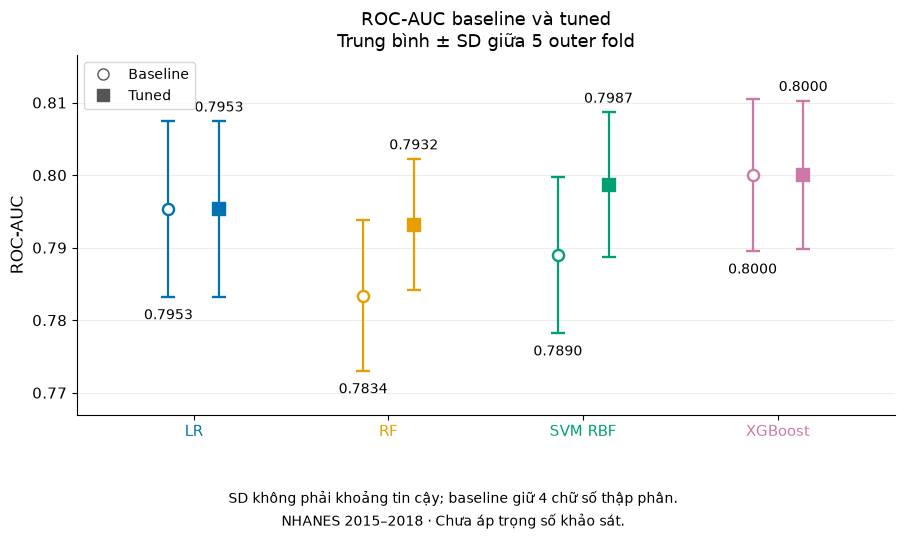

In [2]:
auc_figure, ax = plt.subplots(figsize=(9.4, 5.7))
auc_bounds = []
for position, (model, color) in enumerate(model_colors.items()):
    row = comparison_plot.loc[(model, "ROC-AUC")]
    saved_fold_values = fold_metrics_plot.loc[model, "ROC-AUC"]
    np.testing.assert_allclose(
        [row["tuned_mean"], row["tuned_std"]],
        [saved_fold_values.mean(), saved_fold_values.std(ddof=1)],
    )
    baseline_values = row[["baseline_mean", "baseline_std"]].to_numpy(dtype=float)
    np.testing.assert_allclose(baseline_values * 10000, np.round(baseline_values * 10000))
    for variant, offset, marker, face in [
        ("baseline", -0.13, "o", "white"), ("tuned", 0.13, "s", color),
    ]:
        mean, sd = row[f"{variant}_mean"], row[f"{variant}_std"]
        ax.errorbar(
            position + offset, mean, yerr=sd, fmt=marker, color=color,
            markerfacecolor=face, markeredgewidth=1.7, markersize=8,
            capsize=5, elinewidth=1.6,
        )
        below = variant == "baseline"
        ax.annotate(
            f"{mean:.4f}",
            (position + offset, mean - sd if below else mean + sd),
            xytext=(0, -16 if below else 7), textcoords="offset points",
            ha="center", fontsize=10,
        )
        auc_bounds.extend([mean - sd, mean + sd])
ax.set(
    xticks=range(len(model_colors)), xticklabels=list(model_colors),
    ylabel="ROC-AUC", ylim=(min(auc_bounds) - 0.006, max(auc_bounds) + 0.006),
    title="ROC-AUC baseline và tuned\nTrung bình ± SD giữa 5 outer fold",
)
ax.set_xlim(-0.6, 3.6)
for tick, color in zip(ax.get_xticklabels(), model_colors.values()):
    tick.set_color(color)
ax.grid(axis="y", alpha=0.22)
ax.legend(handles=[
    Line2D([], [], marker="o", color="#555555", markerfacecolor="white",
           linestyle="none", markersize=8, label="Baseline"),
    Line2D([], [], marker="s", color="#555555", linestyle="none",
           markersize=8, label="Tuned"),
], loc="upper left")
auc_figure.subplots_adjust(bottom=0.23, top=0.86, left=0.10, right=0.97)
auc_figure.text(0.5, 0.075, "SD không phải khoảng tin cậy; baseline giữ 4 chữ số thập phân.",
                ha="center", fontsize=10)
auc_figure.text(0.5, 0.035, "NHANES 2015–2018 · Chưa áp trọng số khảo sát.",
                ha="center", fontsize=10)
save_png(auc_figure, figures_dir / "auc_baseline_tuned.png")
plt.show()
plt.close(auc_figure)


## ROC và precision–recall

AUC/AP trên hình tính từ OOF gộp, khác trung bình fold; đường tham chiếu PR là tỷ lệ nhãn 1 trong mẫu.

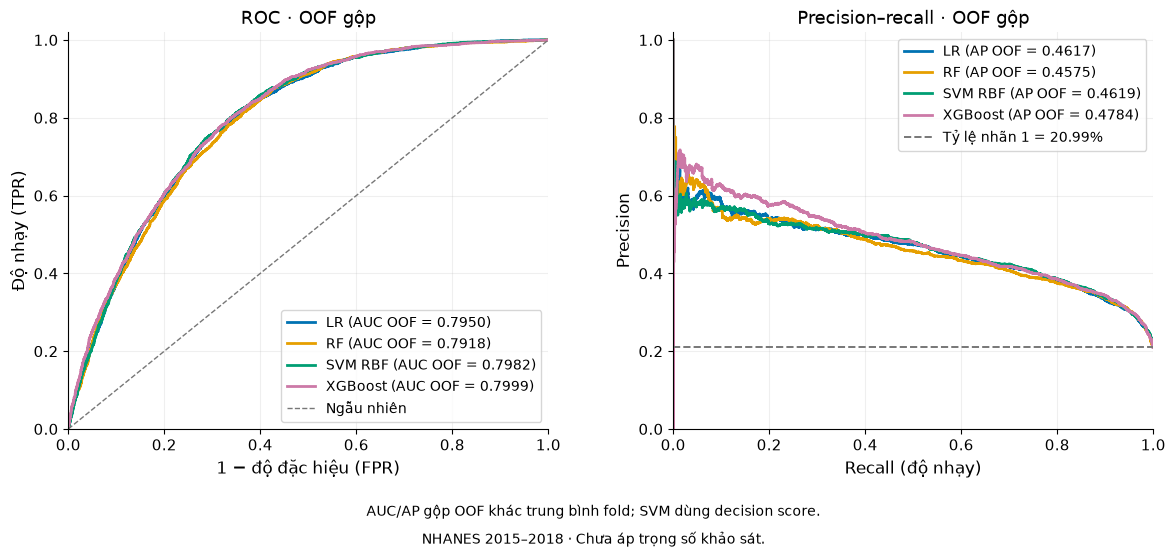

In [3]:
curves_figure, axes = plt.subplots(1, 2, figsize=(14, 6.2))
for model, data in oof_plot.items():
    metrics = pooled_oof_metrics.loc[model]
    fpr, tpr, _ = roc_curve(data["y_true"], data["score"])
    precision, recall, _ = precision_recall_curve(data["y_true"], data["score"])
    axes[0].plot(
        fpr, tpr, color=model_colors[model], linewidth=2,
        label=f"{model} (AUC OOF = {metrics['AUC_OOF']:.4f})",
    )
    axes[1].plot(
        recall, precision, color=model_colors[model], linewidth=2,
        drawstyle="steps-post", label=f"{model} (AP OOF = {metrics['AP_OOF']:.4f})",
    )
axes[0].plot([0, 1], [0, 1], "--", color="#777777", linewidth=1, label="Ngẫu nhiên")
axes[1].axhline(
    sample_prevalence, linestyle="--", color="#777777", linewidth=1.4,
    label=f"Tỷ lệ nhãn 1 = {sample_prevalence:.2%}",
)
axes[0].set(xlabel="1 − độ đặc hiệu (FPR)", ylabel="Độ nhạy (TPR)", title="ROC · OOF gộp")
axes[1].set(xlabel="Recall (độ nhạy)", ylabel="Precision", title="Precision–recall · OOF gộp")
for axis, location in zip(axes, ["lower right", "upper right"]):
    axis.set_xlim(0, 1)
    axis.set_ylim(0, 1.02)
    axis.grid(alpha=0.20)
    axis.legend(loc=location)
curves_figure.subplots_adjust(bottom=0.23, top=0.87, wspace=0.26)
curves_figure.text(0.5, 0.09, "AUC/AP gộp OOF khác trung bình fold; SVM dùng decision score.",
                   ha="center", fontsize=10)
curves_figure.text(0.5, 0.045, "NHANES 2015–2018 · Chưa áp trọng số khảo sát.",
                   ha="center", fontsize=10)
save_png(curves_figure, figures_dir / "roc_pr_oof_tuned.png")
plt.show()
plt.close(curves_figure)


## Confusion matrix

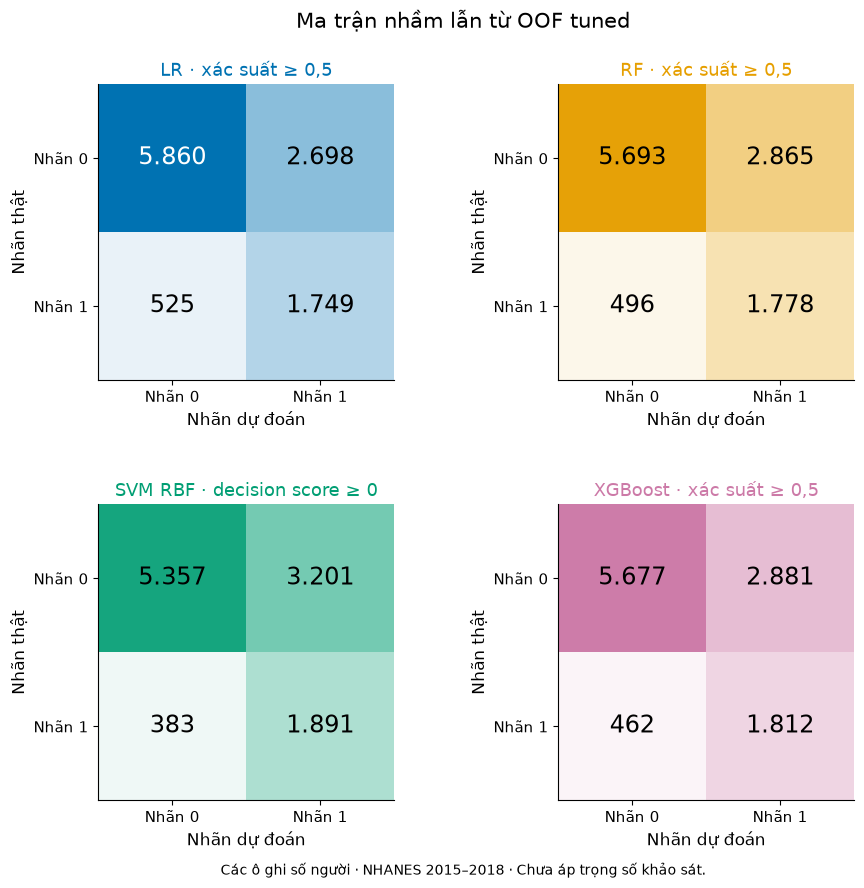

In [4]:
confusion_oof = {
    model: confusion_matrix(data["y_true"], data["prediction"], labels=[0, 1])
    for model, data in oof_plot.items()
}
matrix_max = max(matrix.max() for matrix in confusion_oof.values())
cm_figure, axes = plt.subplots(2, 2, figsize=(10.5, 9.3))
for axis, (model, matrix) in zip(axes.flat, confusion_oof.items()):
    color_map = LinearSegmentedColormap.from_list(model, ["#FFFFFF", model_colors[model]])
    axis.imshow(matrix, cmap=color_map, vmin=0, vmax=matrix_max)
    for actual in range(2):
        for predicted in range(2):
            value = matrix[actual, predicted]
            rgb = color_map(value / matrix_max)[:3]
            luminance = np.dot(rgb, [0.2126, 0.7152, 0.0722])
            axis.text(
                predicted, actual, f"{value:,}".replace(",", "."),
                ha="center", va="center", fontsize=17,
                color="black" if luminance > 0.48 else "white",
            )
    threshold = "decision score ≥ 0" if model == "SVM RBF" else "xác suất ≥ 0,5"
    axis.set(
        xticks=[0, 1], yticks=[0, 1],
        xticklabels=["Nhãn 0", "Nhãn 1"], yticklabels=["Nhãn 0", "Nhãn 1"],
        xlabel="Nhãn dự đoán", ylabel="Nhãn thật",
        title=f"{model} · {threshold}",
    )
    axis.title.set_color(model_colors[model])
    axis.grid(False)
    assert matrix.sum() == len(reference_oof)
cm_figure.suptitle("Ma trận nhầm lẫn từ OOF tuned", y=0.98)
cm_figure.subplots_adjust(bottom=0.13, top=0.90, hspace=0.42, wspace=0.30)
cm_figure.text(0.5, 0.05, "Các ô ghi số người · NHANES 2015–2018 · Chưa áp trọng số khảo sát.",
               ha="center", fontsize=10)
save_png(cm_figure, figures_dir / "confusion_matrices_oof_tuned.png")
plt.show()
plt.close(cm_figure)


## Calibration

Chia xác suất thành 10 nhóm quantile; xác suất bằng nhau ở cùng nhóm nên số người có thể lệch nhau.

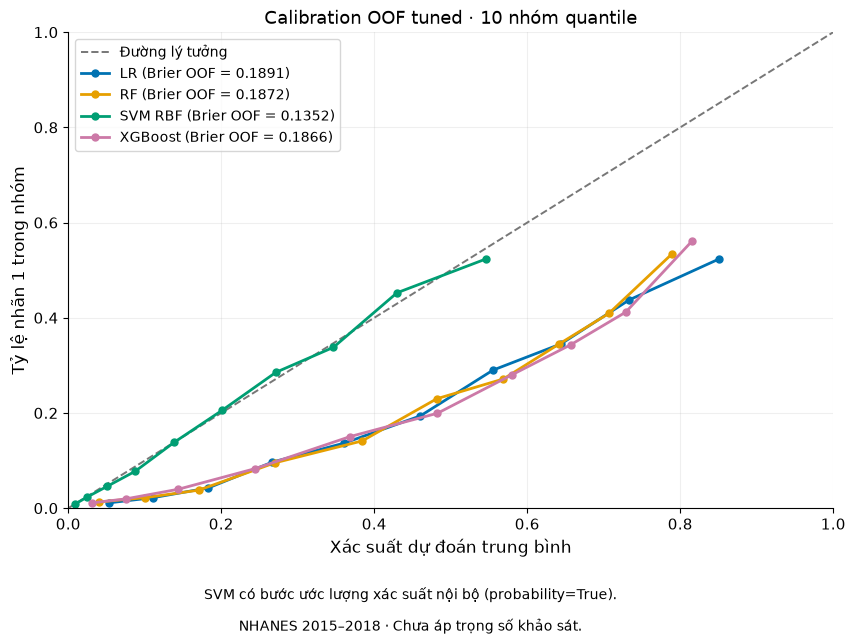

,model,quantile_group,n,mean_probability,positive_rate
0,LR,1,1084,0.0528,0.0111
1,LR,2,1083,0.1111,0.0222
2,LR,3,1083,0.1829,0.0425
3,LR,4,1084,0.2669,0.0969
4,LR,5,1082,0.3610,0.1368
5,LR,6,1083,0.4603,0.1939
6,LR,7,1083,0.5551,0.2899
7,LR,8,1083,0.6444,0.3453
8,LR,9,1083,0.7334,0.4377
9,LR,10,1084,0.8501,0.5231


In [5]:
calibration_rows = []
calibration_figure, ax = plt.subplots(figsize=(9, 7))
ax.plot([0, 1], [0, 1], "--", color="#777777", linewidth=1.4, label="Đường lý tưởng")
for model, data in oof_plot.items():
    probability = data["probability_1"].to_numpy(dtype=float)
    labels = data["y_true"].to_numpy(dtype=int)
    groups = get_calibration_bins(labels, probability).set_index("quantile_group")
    valid = groups["n"].gt(0)
    assert groups["n"].sum() == len(data)
    ax.plot(
        groups.loc[valid, "mean_probability"], groups.loc[valid, "positive_rate"],
        marker="o", markersize=5, linewidth=2, color=model_colors[model],
        label=f"{model} (Brier OOF = {pooled_oof_metrics.loc[model, 'Brier_OOF']:.4f})",
    )
    calibration_rows.append(groups.reset_index().assign(model=model))
calibration_table = pd.concat(calibration_rows, ignore_index=True)[[
    "model", "quantile_group", "lower_bound", "upper_bound",
    "n", "mean_probability", "positive_rate",
]]
calibration_table.to_csv(figures_dir / "calibration_quantile_bins.csv", index=False)
ax.set(
    xlabel="Xác suất dự đoán trung bình", ylabel="Tỷ lệ nhãn 1 trong nhóm",
    xlim=(0, 1), ylim=(0, 1), title="Calibration OOF tuned · 10 nhóm quantile",
)
ax.grid(alpha=0.20)
ax.legend(loc="upper left")
calibration_figure.subplots_adjust(bottom=0.22, top=0.90, left=0.12, right=0.97)
calibration_figure.text(0.5, 0.09, "SVM có bước ước lượng xác suất nội bộ (probability=True).",
                        ha="center", fontsize=10)
calibration_figure.text(0.5, 0.045, "NHANES 2015–2018 · Chưa áp trọng số khảo sát.",
                        ha="center", fontsize=10)
save_png(calibration_figure, figures_dir / "calibration_oof_tuned.png")
plt.show()
plt.close(calibration_figure)
calibration_table[["model", "quantile_group", "n", "mean_probability", "positive_rate"]].round(4)


In [6]:
figure_names = [
    "auc_baseline_tuned", "roc_pr_oof_tuned",
    "confusion_matrices_oof_tuned", "calibration_oof_tuned",
]
source_files = [
    plot_results_dir / "baseline_tuned_comparison.csv",
    plot_results_dir / "tuned_fold_metrics.csv",
    *[plot_results_dir / f"oof_{model.replace(' ', '_')}.parquet" for model in model_colors],
]
figure_manifest = {
    "run_id": PLOT_RUN_ID, "unweighted": True, "n": len(reference_oof),
    "prevalence": sample_prevalence, "model_colors": model_colors,
    "auc_error_bar": "SD across 5 outer folds (ddof=1), not confidence interval",
    "baseline_precision": "recorded values: 4 decimal places",
    "pooled_ranking_score": "SVM decision_function; other models probability_1",
    "thresholds": {"SVM RBF": "score >= 0", "others": "probability_1 >= 0.5"},
    "calibration": "10 model-specific quantile groups; ties kept together",
    "svm_probability": "internal probability estimation; no additional calibration",
    "matplotlib_version": matplotlib.__version__,
    "source_sha256": {
        str(path): hashlib.sha256(path.read_bytes()).hexdigest() for path in source_files
    },
    "figures": [f"{name}.png" for name in figure_names],
}
(figures_dir / "figure_manifest.json").write_text(
    json.dumps(figure_manifest, ensure_ascii=False, indent=2), encoding="utf-8",
)
pd.DataFrame({
    "Hình": figure_names,
    "PNG 300 dpi": [str(figures_dir / f"{name}.png") for name in figure_names],
})


,Hình,PNG 300 dpi,PDF
0,auc_baseline_tuned,..\results\figures\auc_baseline_tuned.png,..\results\figures\auc_baseline_tuned.pdf
1,roc_pr_oof_tuned,..\results\figures\roc_pr_oof_tuned.png,..\results\figures\roc_pr_oof_tuned.pdf
2,confusion_matrices_oof_tuned,..\results\figures\confusion_matrices_oof_tune...,..\results\figures\confusion_matrices_oof_tune...
3,calibration_oof_tuned,..\results\figures\calibration_oof_tuned.png,..\results\figures\calibration_oof_tuned.pdf
